# Demo · Buscador de fotos en español

**Aprendizaje Automático III · Parcial II · Grupo A7**
**Equipo:** 
**Integrantes:** Emilio Frausto Ortiz, Juan, Rodrigo Rosales

Este notebook es solo para enseñar el sistema funcionando. Usa los modelos que ya entrenamos en `AA3_P2_Avance2_Buscador_Imagenes.ipynb`, así que aquí no se entrena nada y todo corre en CPU.

**Para correrla:** usar el kernel del venv `ml3`, darle *Run All* y abrir la liga que aparece al final.

## 1. Configuración
Se puede cambiar `VARIANTE` por `"ligera"`, o `CARPETA` por una carpeta con otras fotos.

In [7]:
import json, time
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
import onnxruntime as ort, gradio as gr
from PIL import Image, ImageOps
from tokenizers import Tokenizer

VARIANTE = "ligera"                      # "ligera" o "mediana"
OUT = Path.cwd() / "salidas_avance2"
CARPETA = OUT / "demo_fotos"              # 3600 fotos de XM3600 que el modelo no vio
EXT = {".jpg", ".jpeg", ".png", ".webp"}

## 2. Cargar modelos
Usamos imagen int8 + texto fp32, porque fue la mejor combinación entre peso y calidad.

In [8]:
s_img = ort.InferenceSession(str(OUT / f"{VARIANTE}_imagen_int8.onnx"), providers=["CPUExecutionProvider"])
s_txt = ort.InferenceSession(str(OUT / f"{VARIANTE}_texto_fp32.onnx"), providers=["CPUExecutionProvider"])
META = json.load(open(OUT / f"{VARIANTE}_meta.json", encoding="utf-8"))
tok = Tokenizer.from_file(str(OUT / f"{VARIANTE}_tokenizer.json"))
tok.enable_truncation(META["max_len"]); tok.enable_padding(pad_id=0, pad_token="<pad>", length=META["max_len"])

def vector_frase(frase):
    e = tok.encode(frase)
    ids, am = np.array([e.ids], np.int64), np.array([e.attention_mask], np.int64)
    return s_txt.run(None, {"input_ids": ids, "attention_mask": am})[0][0]

def preparar(ruta):
    # Lado corto a 224 y recorte central
    im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    k = 224 / min(im.size); im = im.resize((round(im.width * k), round(im.height * k)), Image.LANCZOS)
    x, y = (im.width - 224) // 2, (im.height - 224) // 2
    return np.asarray(im.crop((x, y, x + 224, y + 224)), np.float32).transpose(2, 0, 1) / 255

print("Modelo:", META["version"])

Modelo: ligera-v1-20261105


## 3. Indexar las fotos
Cada foto se convierte en un vector una sola vez. Si agregamos fotos, solo se calculan las nuevas, sin volver a entrenar.

In [9]:
def indexar():
    archivos = sorted(p.name for p in CARPETA.iterdir() if p.suffix.lower() in EXT)
    idx, viejos = CARPETA / f"indice_{VARIANTE}.npz", {}
    if idx.exists():
        z = np.load(idx)
        if str(z["version"]) == META["version"]:          # otra versión del modelo: se recalcula todo
            viejos = dict(zip(z["archivos"].tolist(), z["vectores"]))
    nuevos = [a for a in archivos if a not in viejos]
    t = time.time()
    for a in nuevos:
        viejos[a] = s_img.run(None, {"imagen": preparar(CARPETA / a)[None]})[0][0]
    if nuevos:
        np.savez(idx, vectores=np.stack([viejos[a] for a in archivos]), archivos=np.array(archivos), version=META["version"])
    print(f"{len(archivos)} fotos | {len(nuevos)} nuevas en {time.time() - t:.1f} s")
    return archivos, np.stack([viejos[a] for a in archivos])

ARCHIVOS, VEC = indexar()

3600 fotos | 0 nuevas en 0.0 s


## 4. Buscar con prompts
La frase se convierte en un vector y lo comparamos contra el de cada foto. El número arriba de cada foto indica qué tan parecida es.

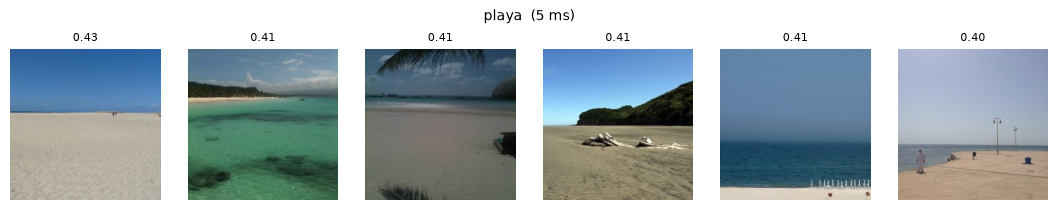

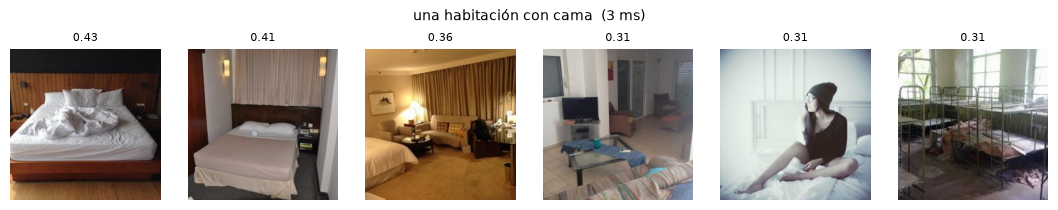

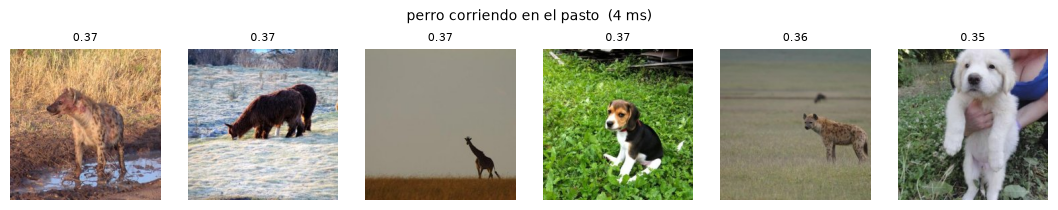

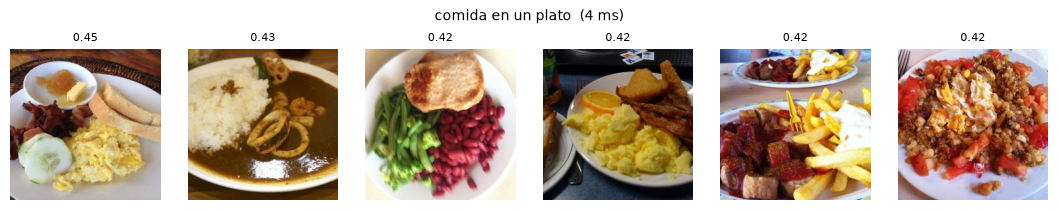

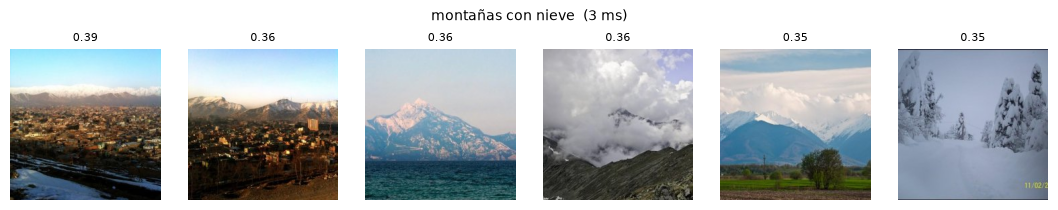

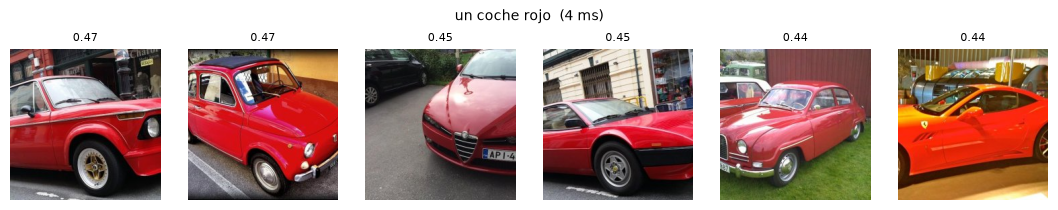

In [10]:
def buscar(frase, k=12):
    s = VEC @ vector_frase(frase); top = np.argsort(-s)[:k]
    return [(str(CARPETA / ARCHIVOS[i]), f"{s[i]:.2f}") for i in top]

def mostrar(frase, k=6):
    t = time.perf_counter(); r = buscar(frase, k); ms = 1000 * (time.perf_counter() - t)
    fig, ax = plt.subplots(1, k, figsize=(k * 1.8, 2.1)); fig.suptitle(f"{frase}  ({ms:.0f} ms)", fontsize=10)
    for a, (ruta, nota) in zip(ax, r):
        a.imshow(Image.open(ruta)); a.set_title(nota, fontsize=8); a.axis("off")
    plt.tight_layout(); plt.show()

for frase in ["playa", "una habitación con cama", "perro corriendo en el pasto", "comida en un plato",
              "montañas con nieve", "un coche rojo"]:
    mostrar(frase)

## 5. Grupos con nombre
Cada foto va al grupo con nombre más cercano. La pestaña aparece si existe `<variante>_grupos.npz`.

In [11]:
ruta_g = OUT / f"{VARIANTE}_grupos.npz"
HAY_GRUPOS = ruta_g.exists()
if HAY_GRUPOS:
    z = np.load(ruta_g); UMBRAL = float(z["umbral"])
    S = VEC @ z["vectores"].T; j = S.argmax(1); PARECIDO = S.max(1)
    ETIQUETA = np.where(PARECIDO >= UMBRAL, z["nombres"][j], "sin grupo")

def lista_grupos():
    n, c = np.unique(ETIQUETA, return_counts=True)
    return [(f"{a} ({b})", str(a)) for b, a in sorted(zip(c, n), reverse=True)]

def fotos_grupo(nombre, k=24):
    i = np.where(ETIQUETA == nombre)[0]; i = i[np.argsort(-PARECIDO[i])][:k]
    return [str(CARPETA / ARCHIVOS[a]) for a in i]

def renombrar(viejo, nuevo):
    # El nombre queda ligado al grupo: así funciona la idea de "agrupar y luego nombrar"
    nuevo = nuevo.strip() or viejo
    ETIQUETA[ETIQUETA == viejo] = nuevo
    return gr.update(choices=lista_grupos(), value=nuevo), ""

if HAY_GRUPOS: print(len(lista_grupos()), "nombres |", lista_grupos()[:8])

## 6. Abrir la demo
Hay que abrir la liga que aparece abajo. Todo corre en esta computadora.

In [12]:
gr.close_all()   # por si la demo ya estaba abierta
with gr.Blocks(title="Buscador de fotos") as demo:
    gr.Markdown(f"## Buscador de fotos en español · {len(ARCHIVOS)} fotos · modelo {VARIANTE}")
    with gr.Tab("Buscar"):
        frase = gr.Textbox(label="¿Qué foto buscas?", placeholder="perro en la playa")
        k = gr.Slider(6, 30, 12, step=6, label="Resultados")
        galeria = gr.Gallery(columns=6, height=520, label="Fotos más parecidas")
        frase.submit(buscar, [frase, k], galeria)
    if HAY_GRUPOS:
        with gr.Tab("Grupos"):
            inicio = next(v for _, v in lista_grupos() if v not in ("persona", "sin grupo"))
            grupo = gr.Dropdown(lista_grupos(), value=inicio, label="Grupo")
            with gr.Row():
                nuevo = gr.Textbox(label="Nuevo nombre"); boton = gr.Button("Renombrar")
            fotos = gr.Gallery(fotos_grupo(inicio), columns=6, height=520, label="Fotos del grupo")
            grupo.change(fotos_grupo, grupo, fotos)
            boton.click(renombrar, [grupo, nuevo], [grupo, nuevo])

demo.launch(allowed_paths=[str(CARPETA)], prevent_thread_lock=True, inline=False)

Closing server running on port: 7860
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
